# ML Lab 10 — PCA, K-Means & DBSCAN
**Instructor:** Muhammad Khalid Khan  |

## 1. PCA — scikit-learn

PC1 scores: [-2.12132034 -0.70710678  0.70710678  2.12132034]
Explained variance ratio: [1.]


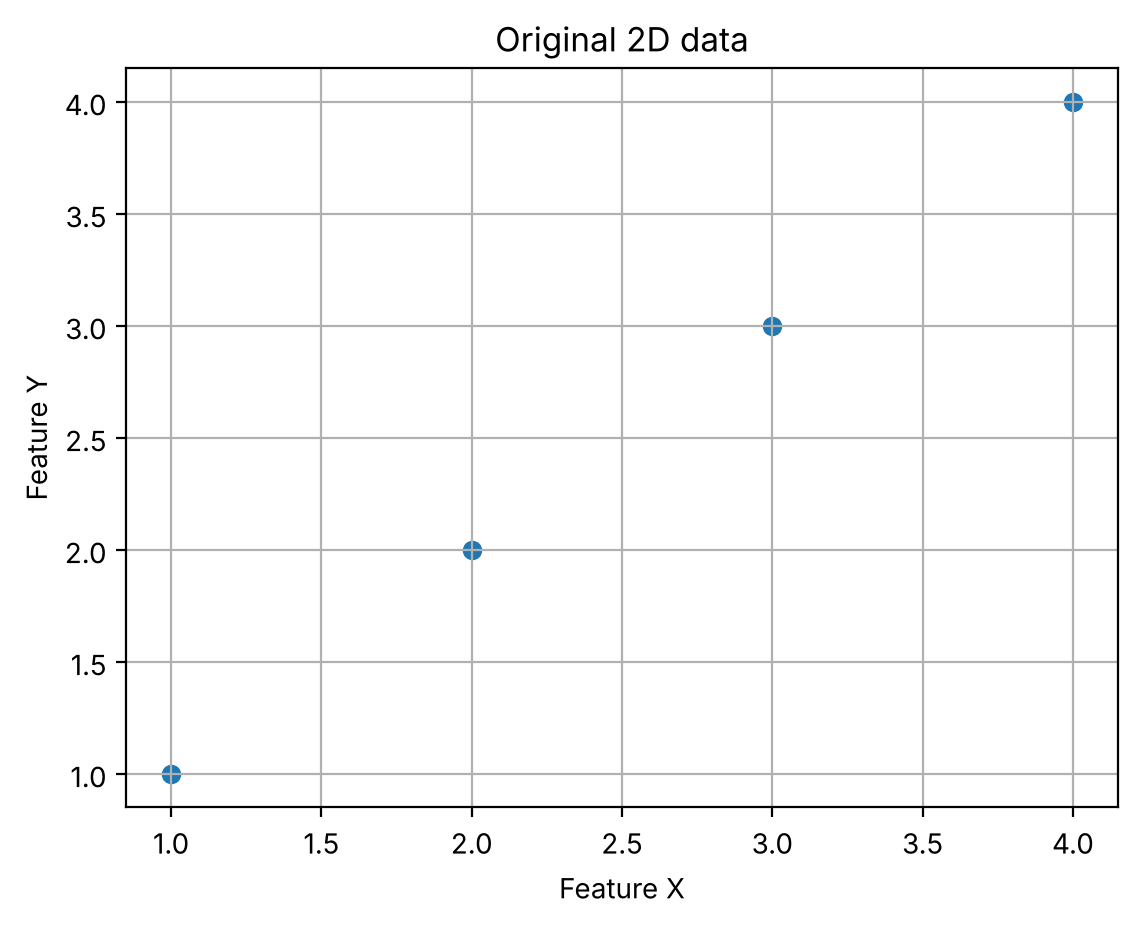

In [1]:
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

X = np.array([[1, 1], [2, 2], [3, 3], [4, 4]])
pca = PCA(n_components=1)
X_reduced = pca.fit_transform(X)
print("PC1 scores:", X_reduced.ravel())
print("Explained variance ratio:", pca.explained_variance_ratio_)
plt.scatter(X[:, 0], X[:, 1])
plt.xlabel("Feature X"); plt.ylabel("Feature Y")
plt.title("Original 2D data"); plt.grid(True); plt.show()

## 2. K-Means — scikit-learn

Labels: [0 0 1 1]
Centroids: [1.5 8.5]
Inertia: 1.0


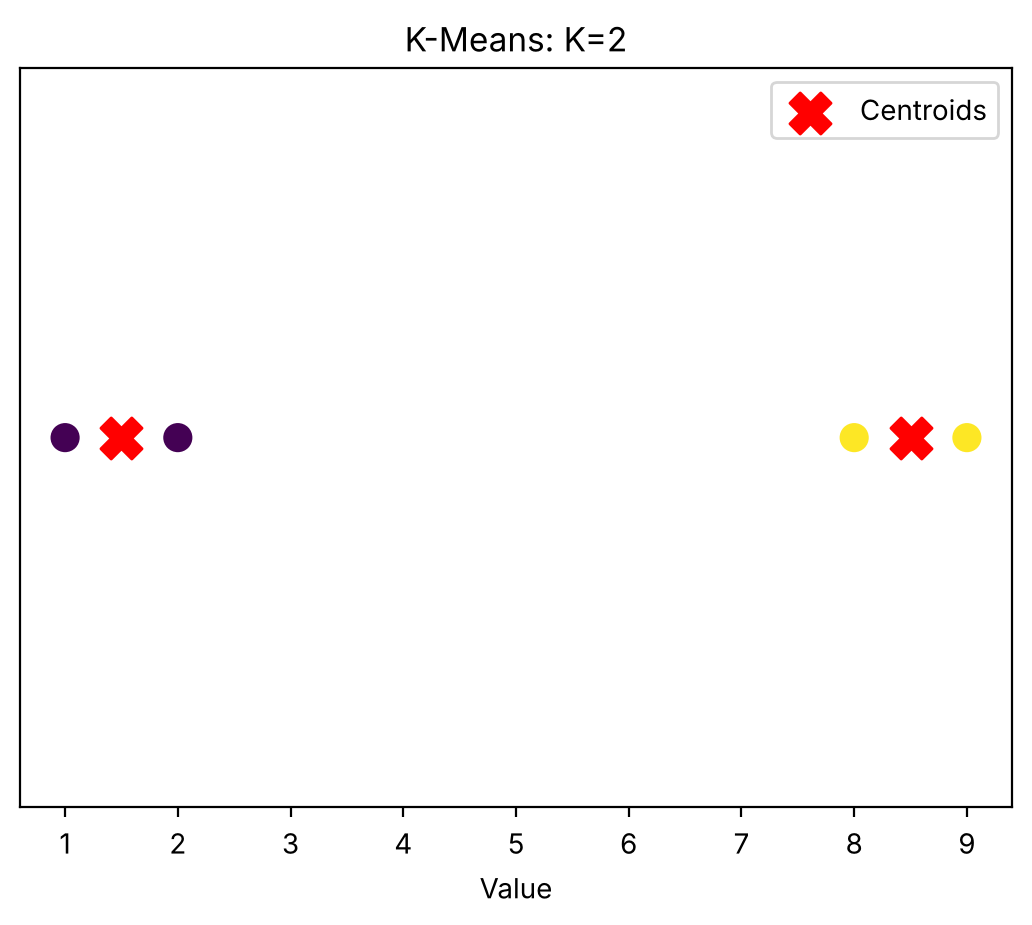

In [2]:
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

X = np.array([[1], [2], [8], [9]])
model = KMeans(n_clusters=2,
      random_state=42,
      n_init=10)


labels = model.fit_predict(X)
print("Labels:", labels)
print("Centroids:", np.sort(model.cluster_centers_.ravel()))
print("Inertia:", model.inertia_)
plt.scatter(X.ravel(), np.zeros(len(X)), c=labels, s=90)
plt.scatter(model.cluster_centers_.ravel(), [0, 0], marker="X", s=220,
            c="red", label="Centroids")
plt.yticks([]); plt.xlabel("Value"); plt.title("K-Means: K=2")
plt.legend(); plt.show()

## 3. DBSCAN — scikit-learn

Values and labels: [(np.float64(1.0), np.int64(0)), (np.float64(1.2), np.int64(0)), (np.float64(1.4), np.int64(0)), (np.float64(5.0), np.int64(1)), (np.float64(5.2), np.int64(1)), (np.float64(9.0), np.int64(-1))]
Number of noise points: 1


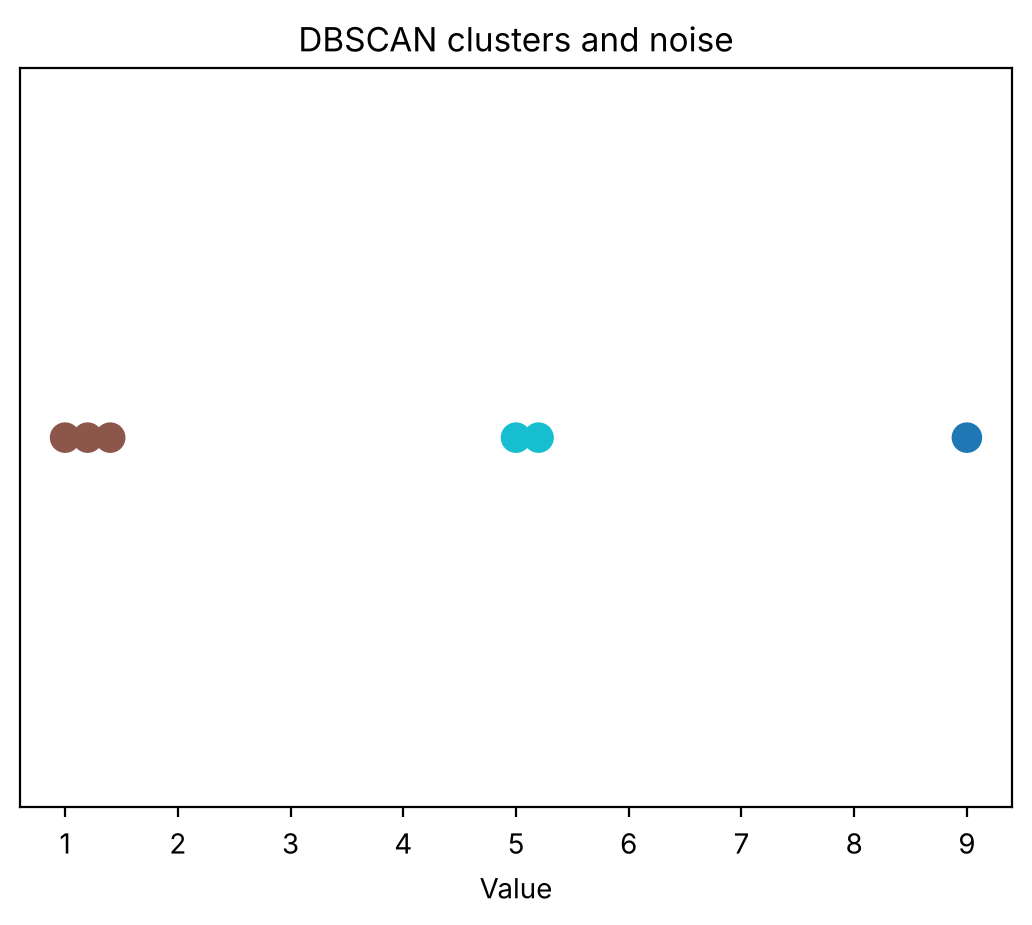

In [3]:
import numpy as np
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt

X = np.array([[1.0], [1.2], [1.4], [5.0], [5.2], [9.0]])
model = DBSCAN(eps=0.3, min_samples=2)
labels = model.fit_predict(X)
print("Values and labels:", list(zip(X.ravel(), labels)))
print("Number of noise points:", np.sum(labels == -1))
plt.scatter(X.ravel(), np.zeros(len(X)), c=labels, cmap="tab10", s=100)
plt.yticks([]); plt.xlabel("Value"); plt.title("DBSCAN clusters and noise")
plt.show()

---
# Class Tasks

## Task 2.4 — PCA on Iris (standardize → PCA(2) → scatter, variance explained)

Variance explained by PC1: 0.7296 (72.96%)
Variance explained by PC2: 0.2285 (22.85%)
Sum (PC1+PC2):             0.9581 (95.81%)
Retains at least 90% of variance? True
All 4 PCs: [0.7296 0.2285 0.0367 0.0052] | cumulative: [0.7296 0.9581 0.9948 1.    ]


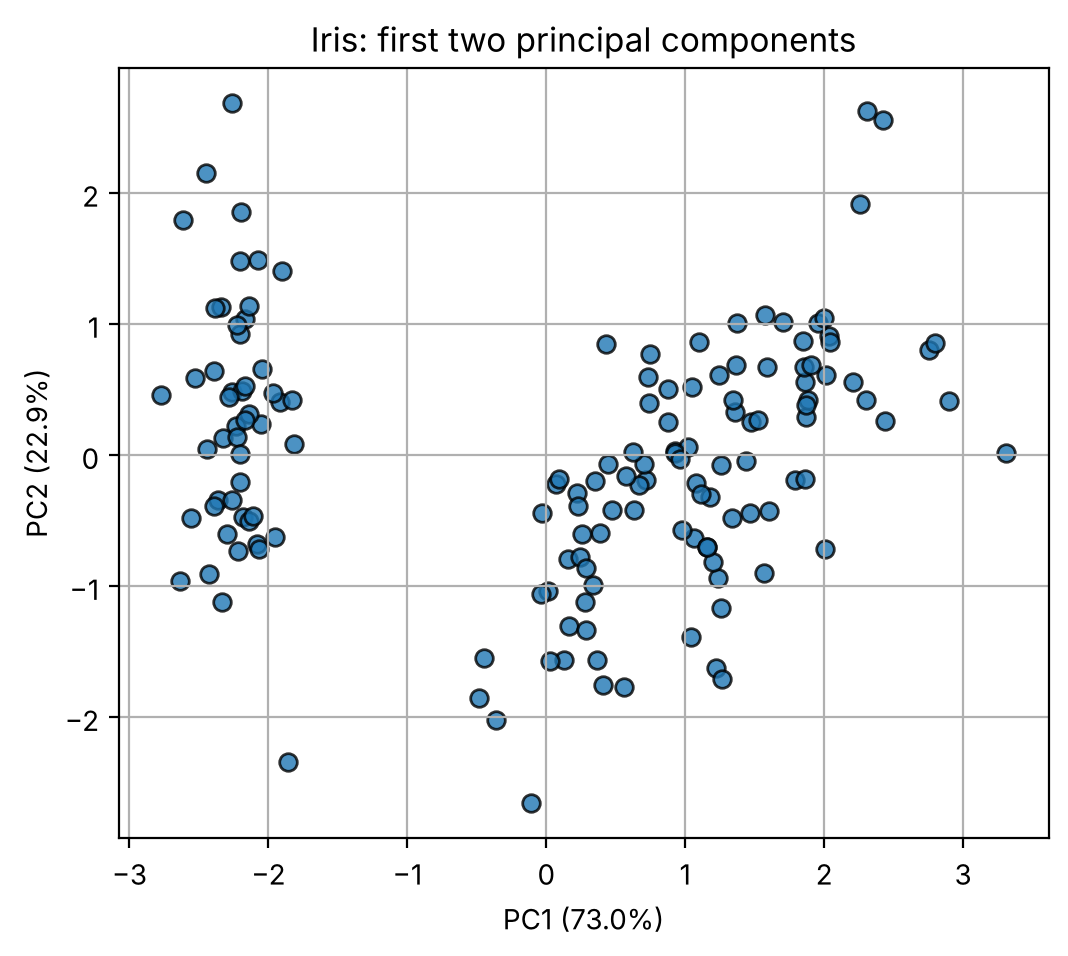

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

iris = load_iris()
X_iris = iris.data                      # features only (no target used for fitting)
X_scaled = StandardScaler().fit_transform(X_iris)

pca = PCA(n_components=2)
Z = pca.fit_transform(X_scaled)

evr = pca.explained_variance_ratio_
print("Variance explained by PC1: %.4f (%.2f%%)" % (evr[0], evr[0]*100))
print("Variance explained by PC2: %.4f (%.2f%%)" % (evr[1], evr[1]*100))
print("Sum (PC1+PC2):             %.4f (%.2f%%)" % (evr.sum(), evr.sum()*100))
print("Retains at least 90%% of variance? %s" % (evr.sum() >= 0.90))

# full spectrum for reference
full = PCA().fit(X_scaled).explained_variance_ratio_
print("All 4 PCs:", np.round(full, 4), "| cumulative:", np.round(np.cumsum(full), 4))

plt.figure(figsize=(6,5))
plt.scatter(Z[:,0], Z[:,1], s=40, edgecolor="k", alpha=0.8)   # unlabeled, as in the task
plt.xlabel("PC1 (%.1f%%)" % (evr[0]*100)); plt.ylabel("PC2 (%.1f%%)" % (evr[1]*100))
plt.title("Iris: first two principal components"); plt.grid(True); plt.show()

## Task 3.4 — K-Means on `make_blobs` (K = 2, 3, 4) + elbow

K=2  inertia = 2752.9291
K=3  inertia = 283.6007
K=4  inertia = 242.8477


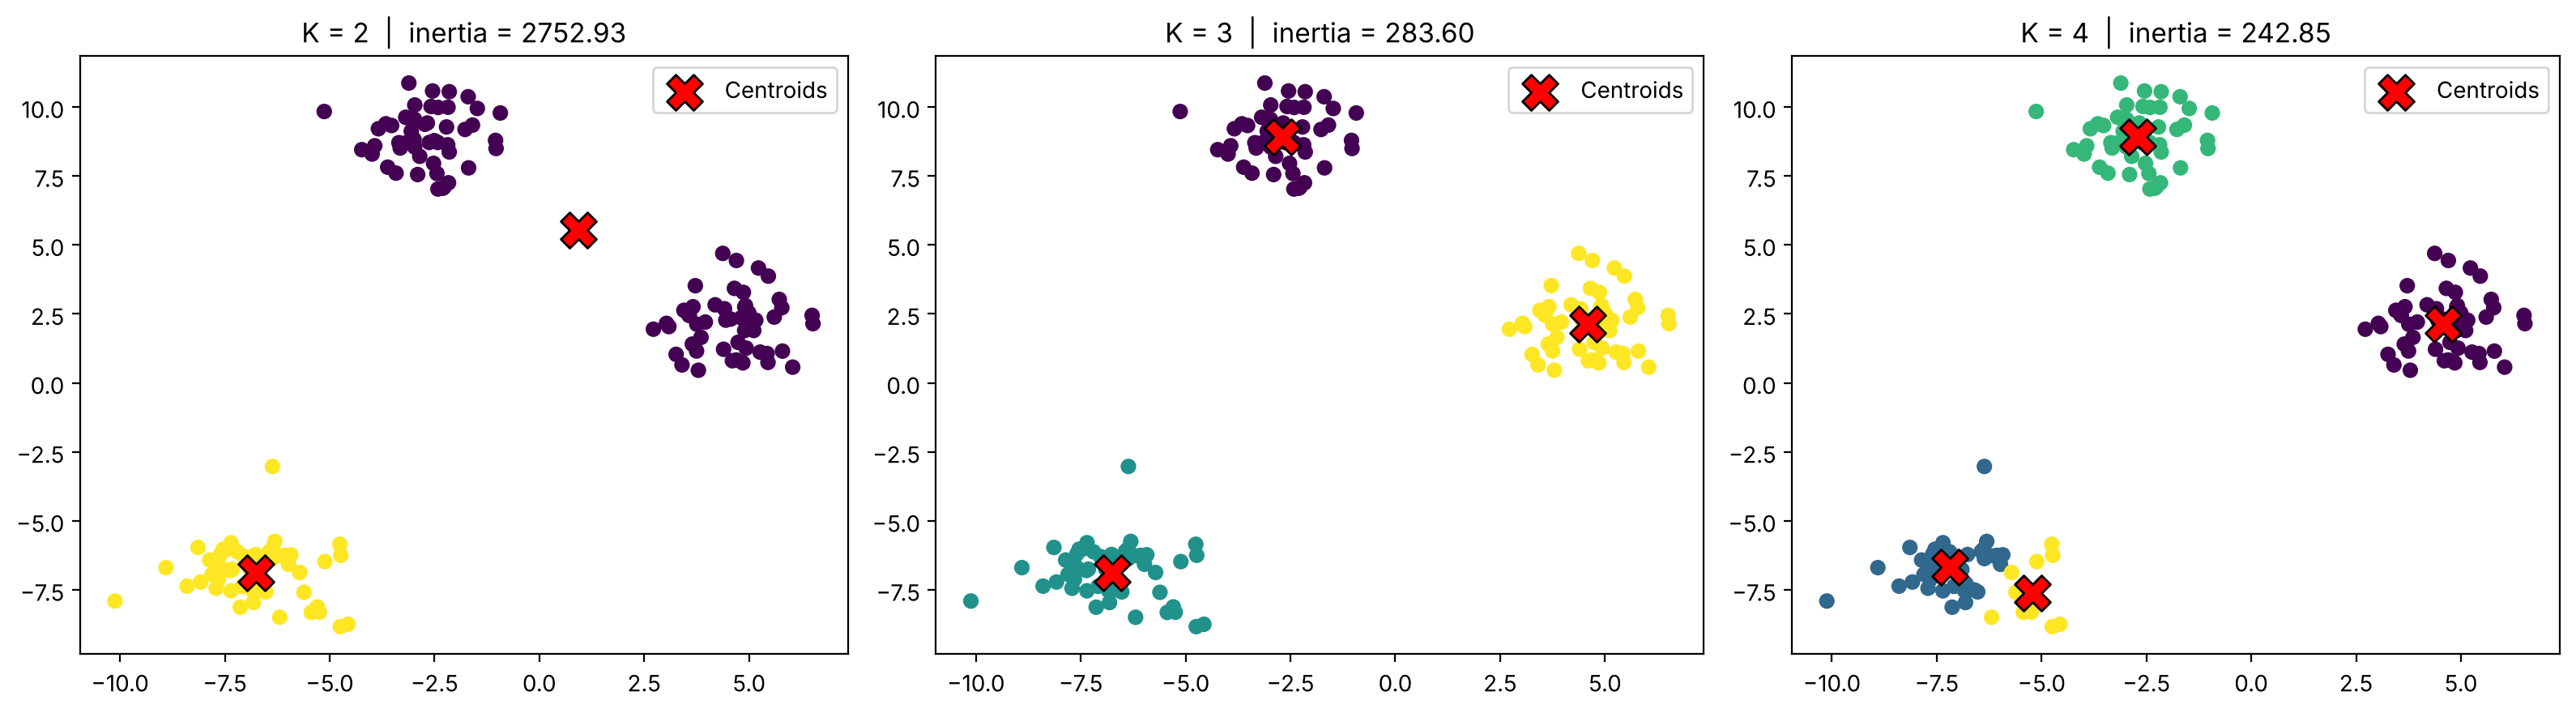

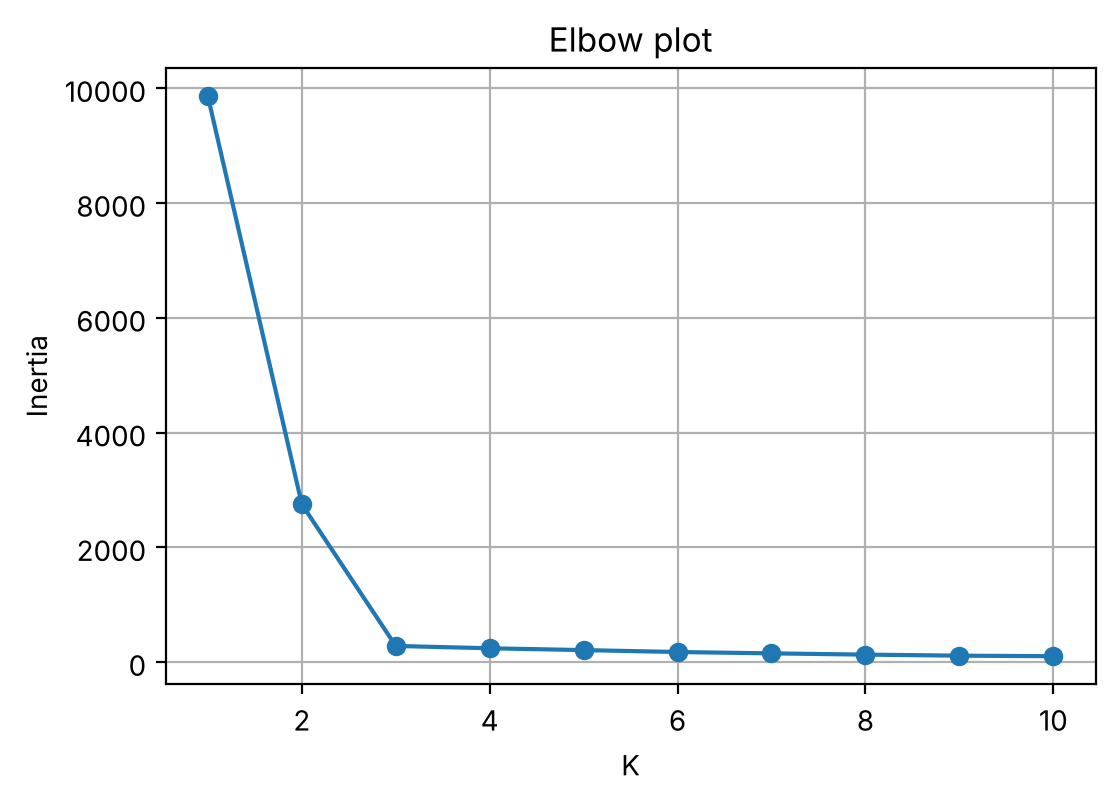

In [5]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

Xb, _ = make_blobs(n_samples=150, centers=3, n_features=2, random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
inertias = {}
for ax, k in zip(axes, [2, 3, 4]):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xb)
    inertias[k] = km.inertia_
    ax.scatter(Xb[:,0], Xb[:,1], c=km.labels_, cmap="viridis", s=35)
    ax.scatter(km.cluster_centers_[:,0], km.cluster_centers_[:,1], marker="X", s=250, c="red", edgecolor="k", label="Centroids")
    ax.set_title("K = %d  |  inertia = %.2f" % (k, km.inertia_)); ax.legend()
    print("K=%d  inertia = %.4f" % (k, km.inertia_))
plt.tight_layout(); plt.show()

# inertia for a range of K: it ALWAYS decreases
ks = range(1, 11)
iner = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xb).inertia_ for k in ks]
plt.figure(figsize=(6,4)); plt.plot(list(ks), iner, "o-")
plt.xlabel("K"); plt.ylabel("Inertia"); plt.title("Elbow plot"); plt.grid(True); plt.show()

In [6]:
# Silhouette score: a measure that does NOT just keep improving as K grows
from sklearn.metrics import silhouette_score
for k in range(2, 8):
    lab = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(Xb)
    print("K=%d  silhouette = %.4f" % (k, silhouette_score(Xb, lab)))

K=2  silhouette = 0.7042
K=3  silhouette = 0.8448
K=4  silhouette = 0.6899
K=5  silhouette = 0.4997
K=6  silhouette = 0.3292
K=7  silhouette = 0.3568


## K-Means: random initialization vs K-Means++

In [7]:
import warnings; warnings.filterwarnings("ignore")
# (a) The manual's comparison, with n_init=10 (best of 10 runs hides differences)
for name in ["random", "k-means++"]:
    km = KMeans(n_clusters=3, init=name, n_init=10, random_state=42).fit(Xb)
    print("%-10s n_init=10  inertia = %.4f  iterations = %d" % (name, km.inertia_, km.n_iter_))

# (b) Fairer test: ONE initialization per run, repeated over 200 seeds
res = {}
for name in ["random", "k-means++"]:
    inert, iters = [], []
    for seed in range(200):
        km = KMeans(n_clusters=3, init=name, n_init=1, random_state=seed).fit(Xb)
        inert.append(km.inertia_); iters.append(km.n_iter_)
    res[name] = (np.array(inert), np.array(iters))
    i = res[name][0]
    print("%-10s n_init=1 x200 | best %.2f | mean %.2f | worst %.2f | runs stuck in bad optimum: %d | mean iters %.2f"
          % (name, i.min(), i.mean(), i.max(), np.sum(i > i.min()*1.05), res[name][1].mean()))

random     n_init=10  inertia = 283.6007  iterations = 3
k-means++  n_init=10  inertia = 283.6007  iterations = 2
random     n_init=1 x200 | best 283.60 | mean 697.00 | worst 2737.55 | runs stuck in bad optimum: 34 | mean iters 3.44


k-means++  n_init=1 x200 | best 283.60 | mean 283.60 | worst 283.60 | runs stuck in bad optimum: 0 | mean iters 2.00


## Task 4.4 — DBSCAN on `make_moons` (eps = 0.3, 0.15, 0.5)

eps=0.30 -> clusters = 2, noise points = 0
eps=0.15 -> clusters = 16, noise points = 26
eps=0.50 -> clusters = 2, noise points = 0


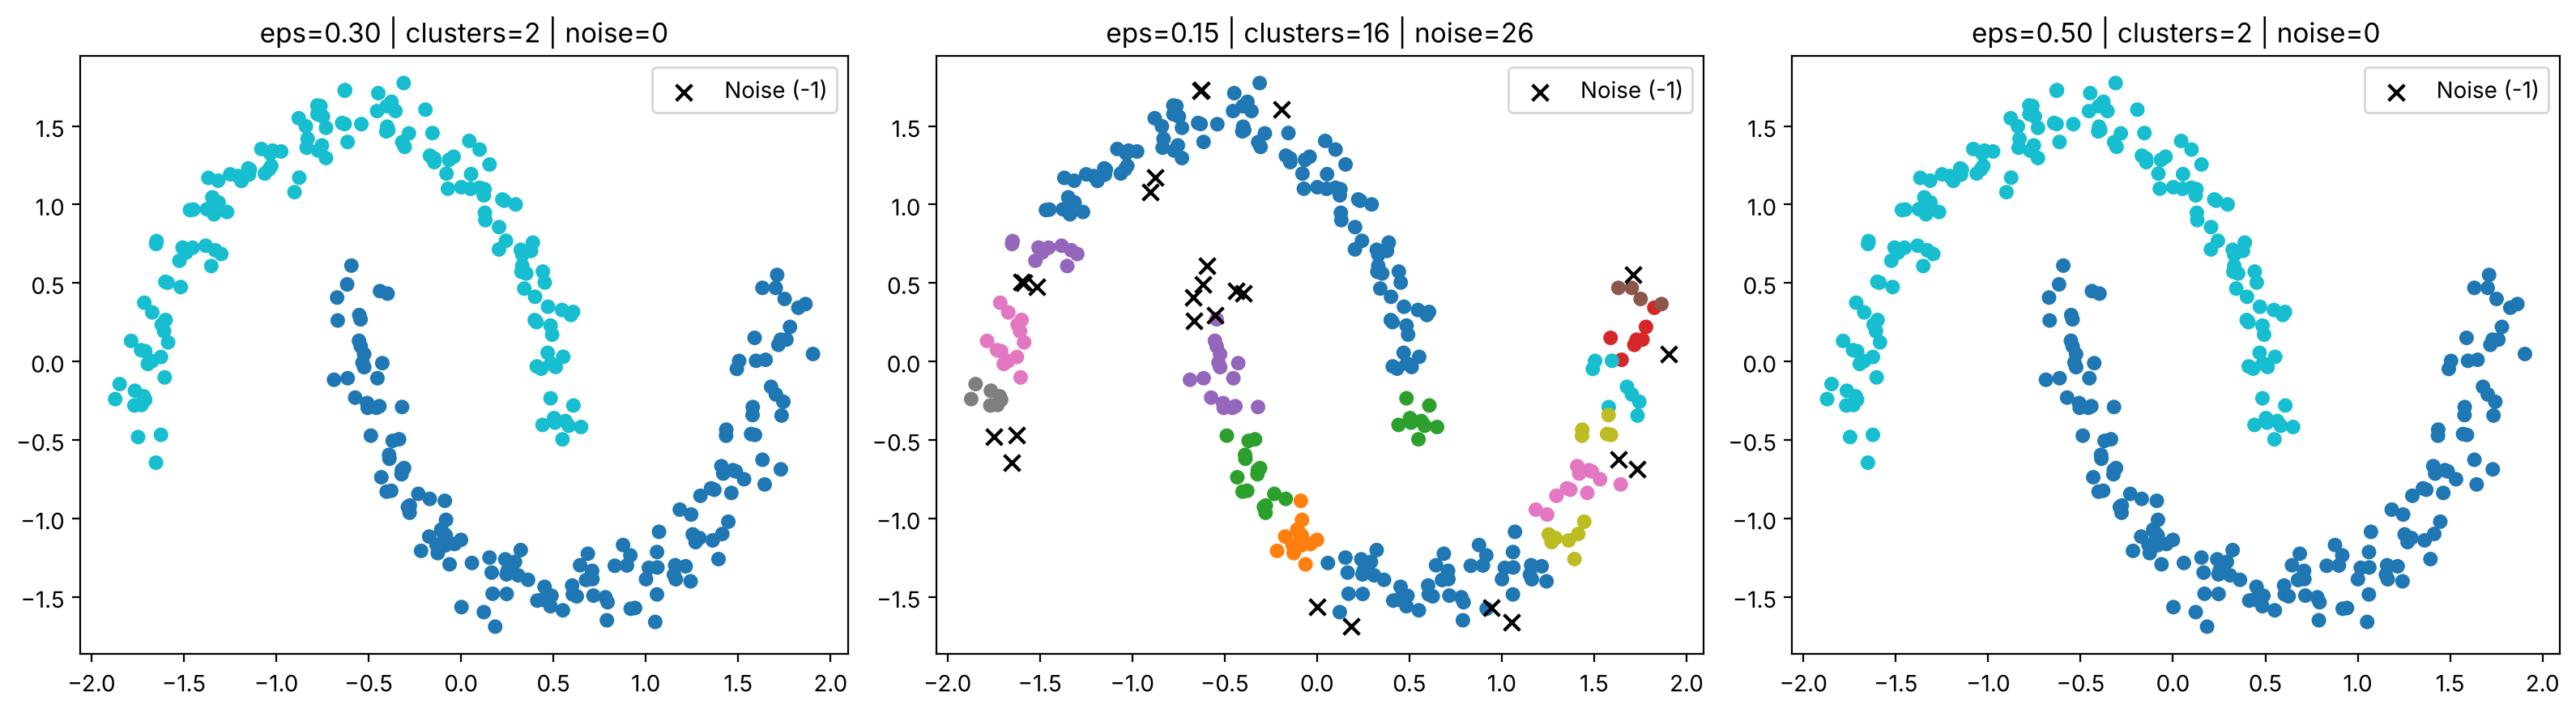

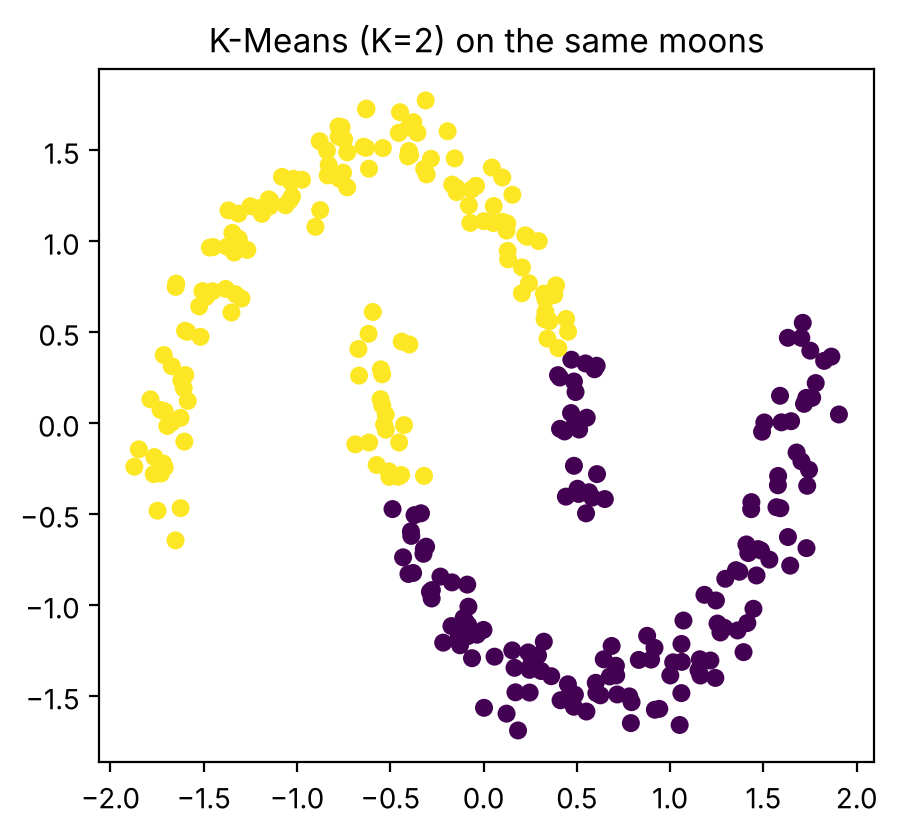

In [8]:
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

Xm, _ = make_moons(n_samples=300, noise=0.06, random_state=42)
Xm_s = StandardScaler().fit_transform(Xm)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, eps in zip(axes, [0.3, 0.15, 0.5]):
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(Xm_s)
    n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
    n_noise = int(np.sum(lab == -1))
    print("eps=%.2f -> clusters = %d, noise points = %d" % (eps, n_clusters, n_noise))
    ax.scatter(Xm_s[lab!=-1,0], Xm_s[lab!=-1,1], c=lab[lab!=-1], cmap="tab10", s=30)
    ax.scatter(Xm_s[lab==-1,0], Xm_s[lab==-1,1], c="k", marker="x", s=50, label="Noise (-1)")
    ax.set_title("eps=%.2f | clusters=%d | noise=%d" % (eps, n_clusters, n_noise)); ax.legend()
plt.tight_layout(); plt.show()

# contrast: K-Means cannot recover the moons
lab_km = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(Xm_s)
plt.figure(figsize=(5,4.5)); plt.scatter(Xm_s[:,0], Xm_s[:,1], c=lab_km, s=30)
plt.title("K-Means (K=2) on the same moons"); plt.show()

## Task 4.4 (second) — Polynomial features + PCA to 3D on a non-linearly-separable dataset

Original shape: (400, 2) -> polynomial shape: (400, 9)
Terms: ['x1' 'x2' 'x1^2' 'x1 x2' 'x2^2' 'x1^3' 'x1^2 x2' 'x1 x2^2' 'x2^3']
Explained variance ratio (3 PCs): [0.2664 0.2605 0.1304] | total = 0.6573


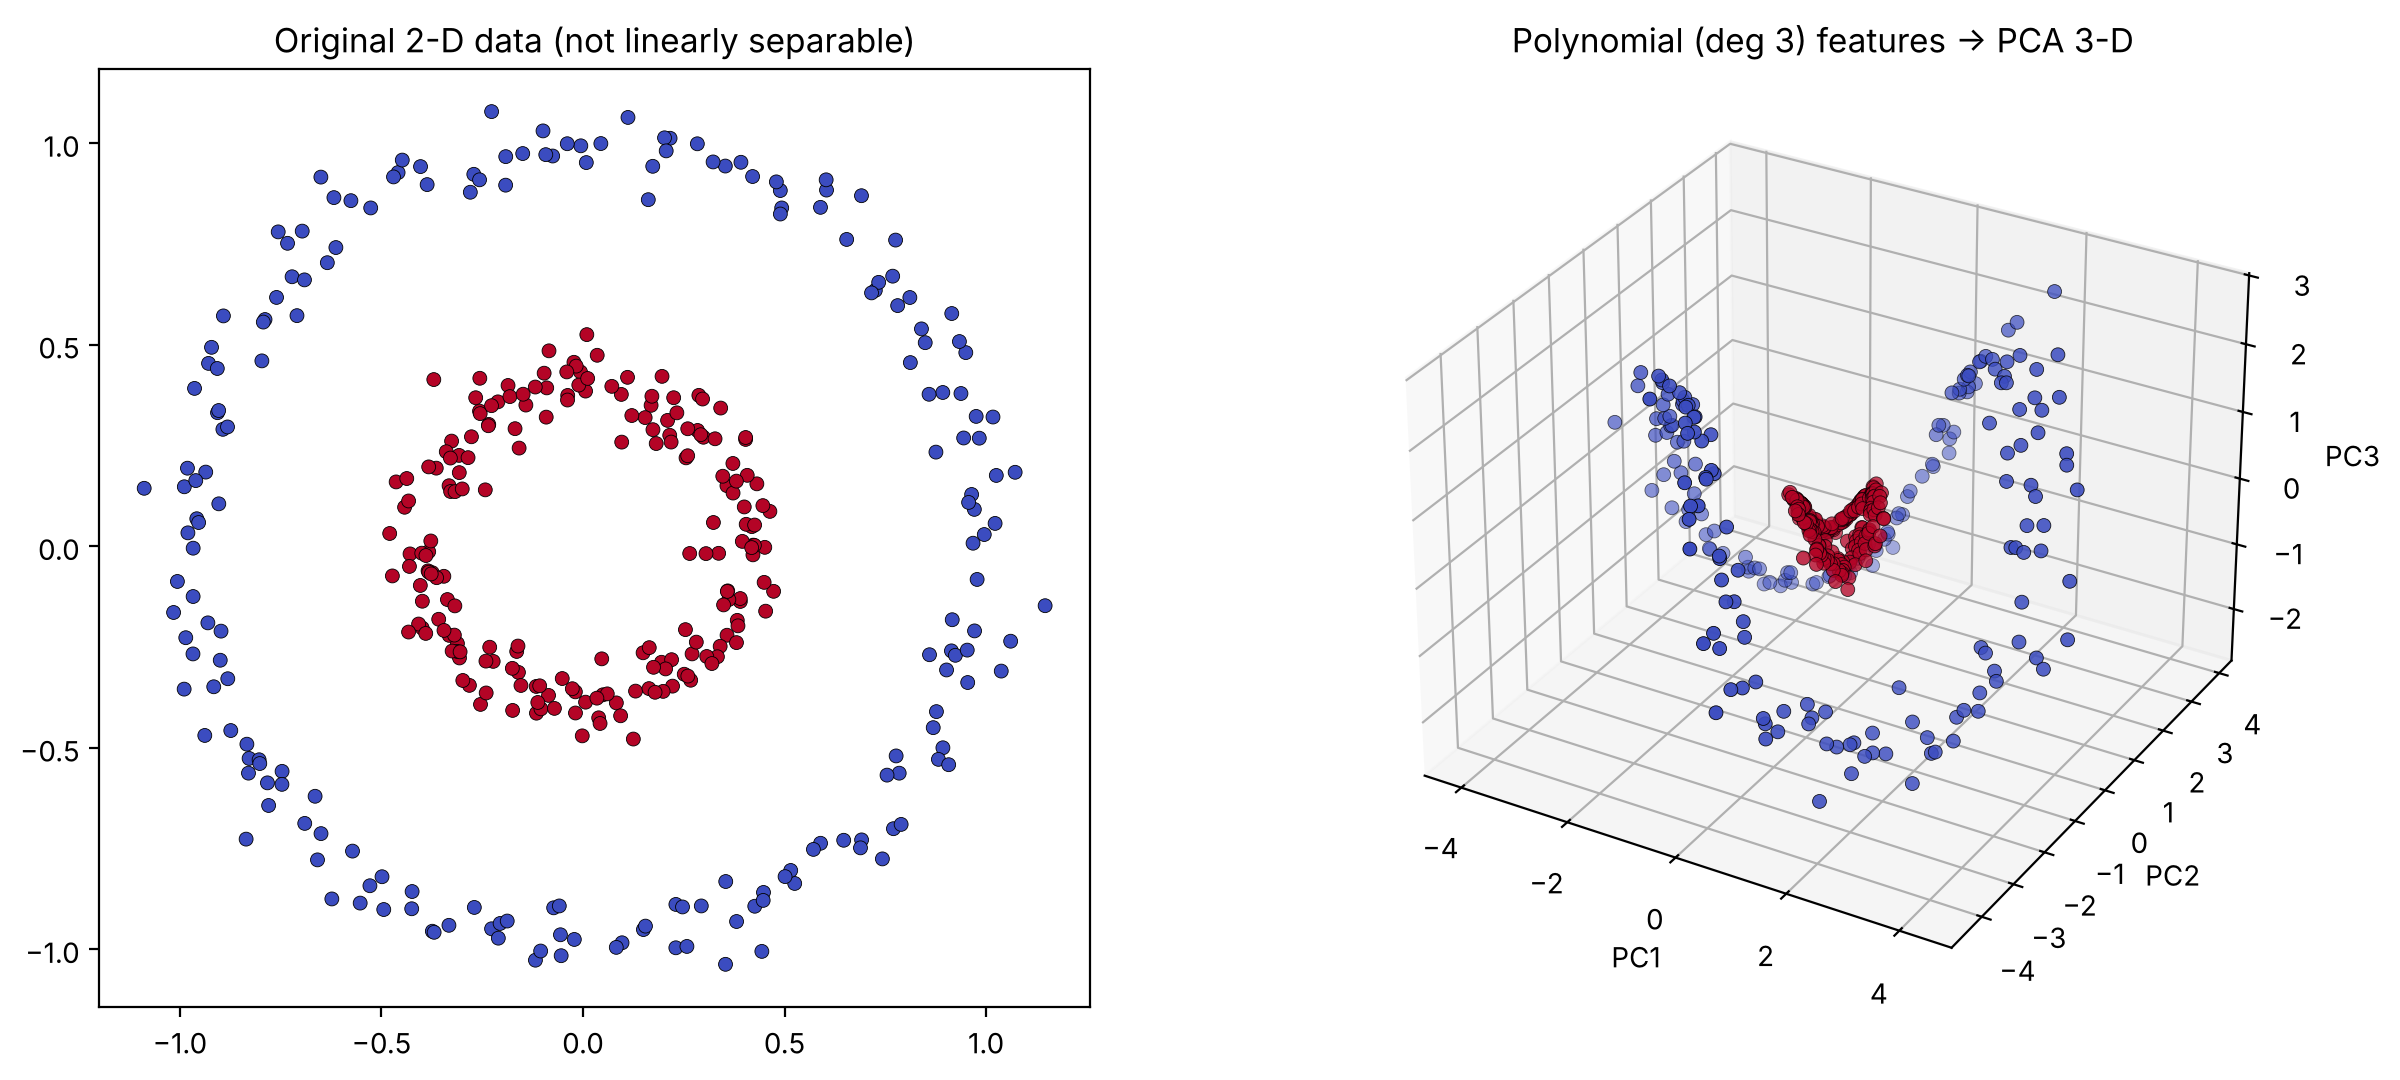

Linear model on original 2-D           train acc = 0.507 | test acc = 0.525
Linear model on 9 polynomial features  train acc = 1.000 | test acc = 1.000
Linear model on 3-D PCA projection     train acc = 0.561 | test acc = 0.517


In [9]:
from sklearn.datasets import make_circles
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from mpl_toolkits.mplot3d import Axes3D  # noqa

# 1) Non-linearly separable data in 2-D: two concentric circles
Xc, yc = make_circles(n_samples=400, factor=0.4, noise=0.05, random_state=42)

# 2) Polynomial expansion (degree 3: 2 features -> 9 features)
poly = PolynomialFeatures(degree=3, include_bias=False)
Xp = poly.fit_transform(Xc)
print("Original shape:", Xc.shape, "-> polynomial shape:", Xp.shape)
print("Terms:", poly.get_feature_names_out(["x1","x2"]))

# 3) Standardize, then PCA to 3 components
Xp_s = StandardScaler().fit_transform(Xp)
pca3 = PCA(n_components=3)
Z3 = pca3.fit_transform(Xp_s)
print("Explained variance ratio (3 PCs):", np.round(pca3.explained_variance_ratio_, 4),
      "| total = %.4f" % pca3.explained_variance_ratio_.sum())

# 4) Visualize: original 2-D vs. 3-D PCA of polynomial features
fig = plt.figure(figsize=(13, 5.5))
ax1 = fig.add_subplot(1, 2, 1)
ax1.scatter(Xc[:,0], Xc[:,1], c=yc, cmap="coolwarm", s=25, edgecolor="k", linewidth=0.3)
ax1.set_title("Original 2-D data (not linearly separable)"); ax1.set_aspect("equal")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.scatter(Z3[:,0], Z3[:,1], Z3[:,2], c=yc, cmap="coolwarm", s=25, edgecolor="k", linewidth=0.3)
ax2.set_xlabel("PC1"); ax2.set_ylabel("PC2"); ax2.set_zlabel("PC3")
ax2.set_title("Polynomial (deg 3) features -> PCA 3-D")
plt.tight_layout(); plt.show()

# Check linear separability quantitatively with a LINEAR classifier
def lin_acc(X, y, name):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
    clf = LogisticRegression(max_iter=5000, C=100).fit(Xtr, ytr)
    print("%-38s train acc = %.3f | test acc = %.3f" % (name, clf.score(Xtr, ytr), clf.score(Xte, yte)))
lin_acc(Xc, yc, "Linear model on original 2-D")
lin_acc(Xp_s, yc, "Linear model on 9 polynomial features")
lin_acc(Z3, yc, "Linear model on 3-D PCA projection")

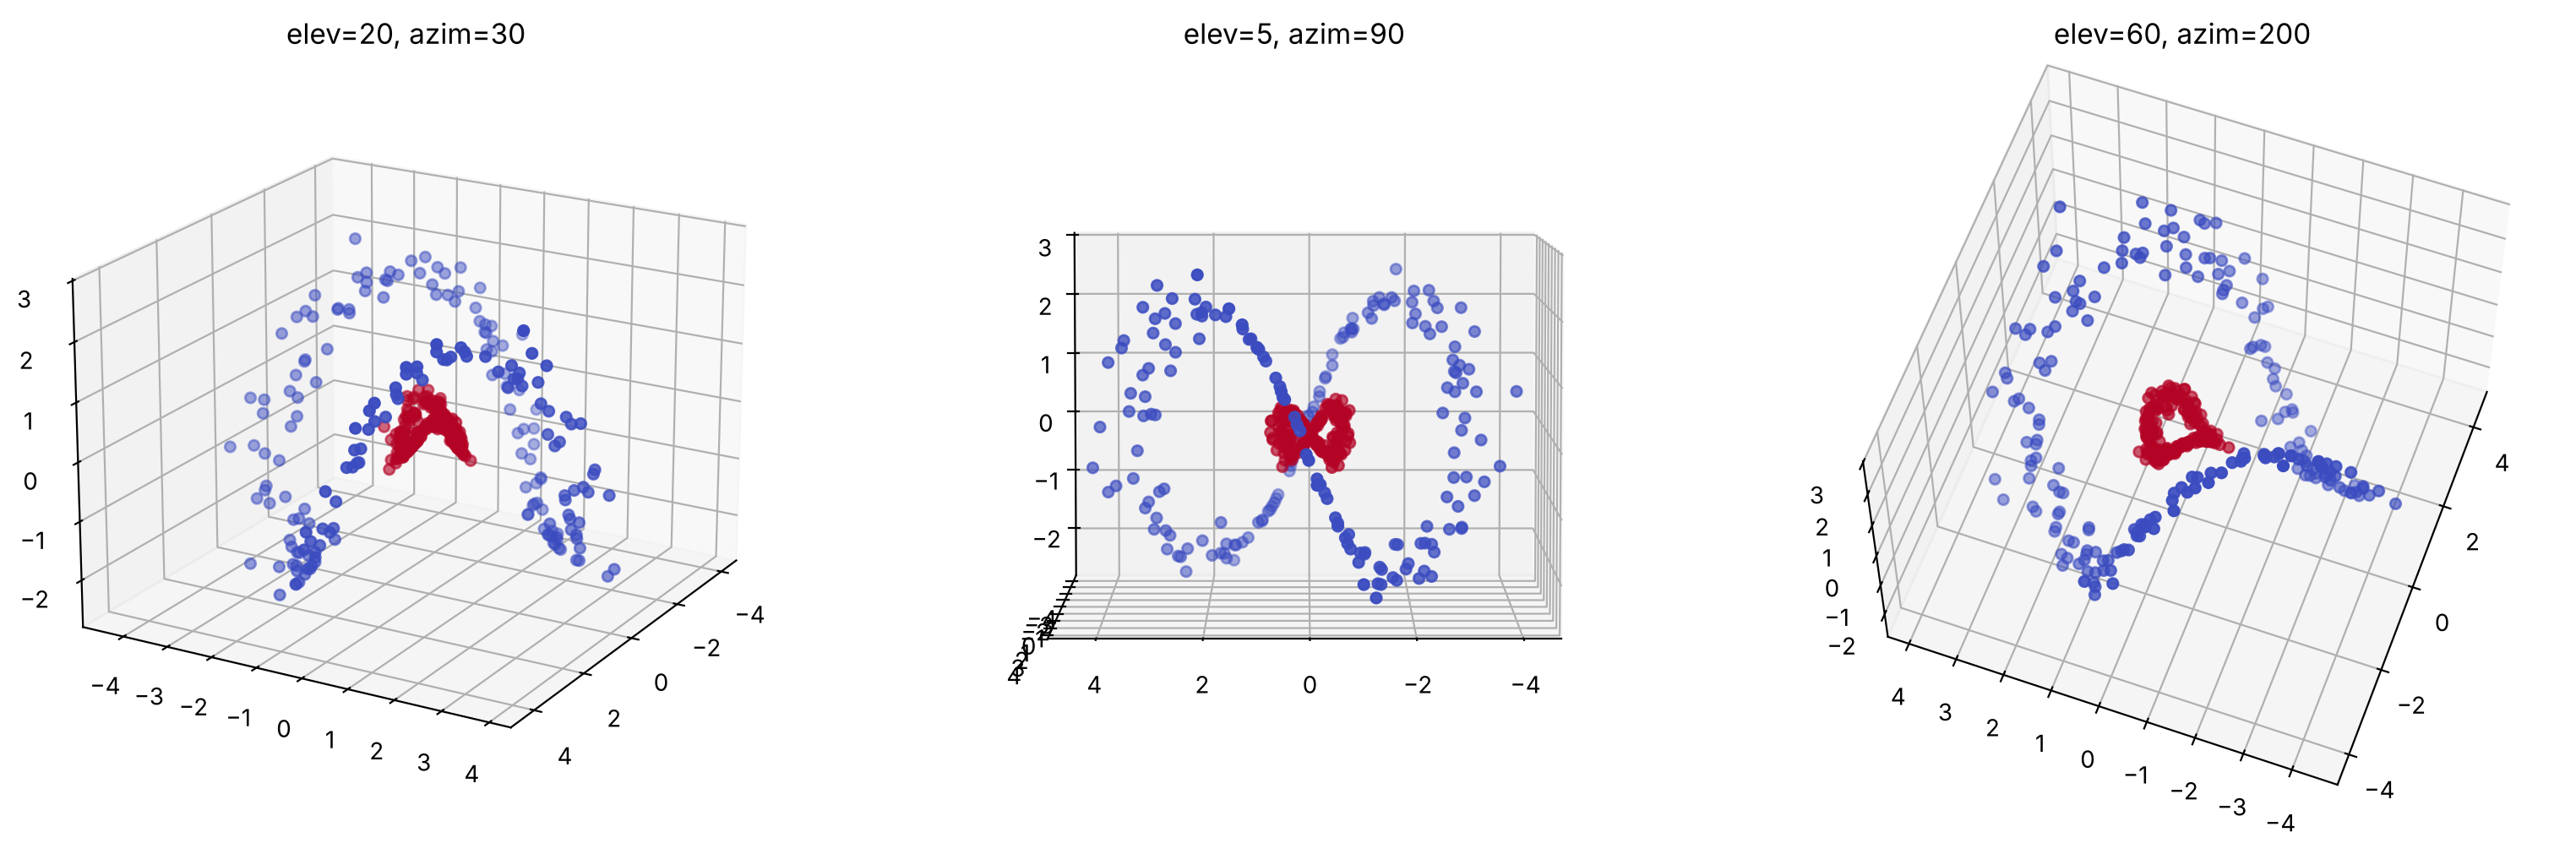

In [10]:
# Zoom in on the best 2 PCs / rotate the 3-D view to look for a separating plane
fig = plt.figure(figsize=(16, 5))
for i, (e, a) in enumerate([(20, 30), (5, 90), (60, 200)]):
    ax = fig.add_subplot(1, 3, i+1, projection="3d")
    ax.scatter(Z3[:,0], Z3[:,1], Z3[:,2], c=yc, cmap="coolwarm", s=20)
    ax.view_init(elev=e, azim=a); ax.set_title("elev=%d, azim=%d" % (e, a))
plt.tight_layout(); plt.show()

**Why does the linear model fail on the 3-D PCA view even though it works on the 9 polynomial features?** PCA is *unsupervised*: it keeps directions of largest variance, not directions that separate the classes. Let's see how many PCs are needed, and what the separating direction looks like.

PCs=1  cumulative var=0.266  linear test acc=0.542
PCs=2  cumulative var=0.527  linear test acc=0.542
PCs=3  cumulative var=0.657  linear test acc=0.517
PCs=4  cumulative var=0.768  linear test acc=0.475
PCs=5  cumulative var=0.860  linear test acc=1.000
PCs=6  cumulative var=0.924  linear test acc=1.000
PCs=7  cumulative var=0.986  linear test acc=1.000
PCs=8  cumulative var=0.993  linear test acc=1.000
PCs=9  cumulative var=1.000  linear test acc=1.000


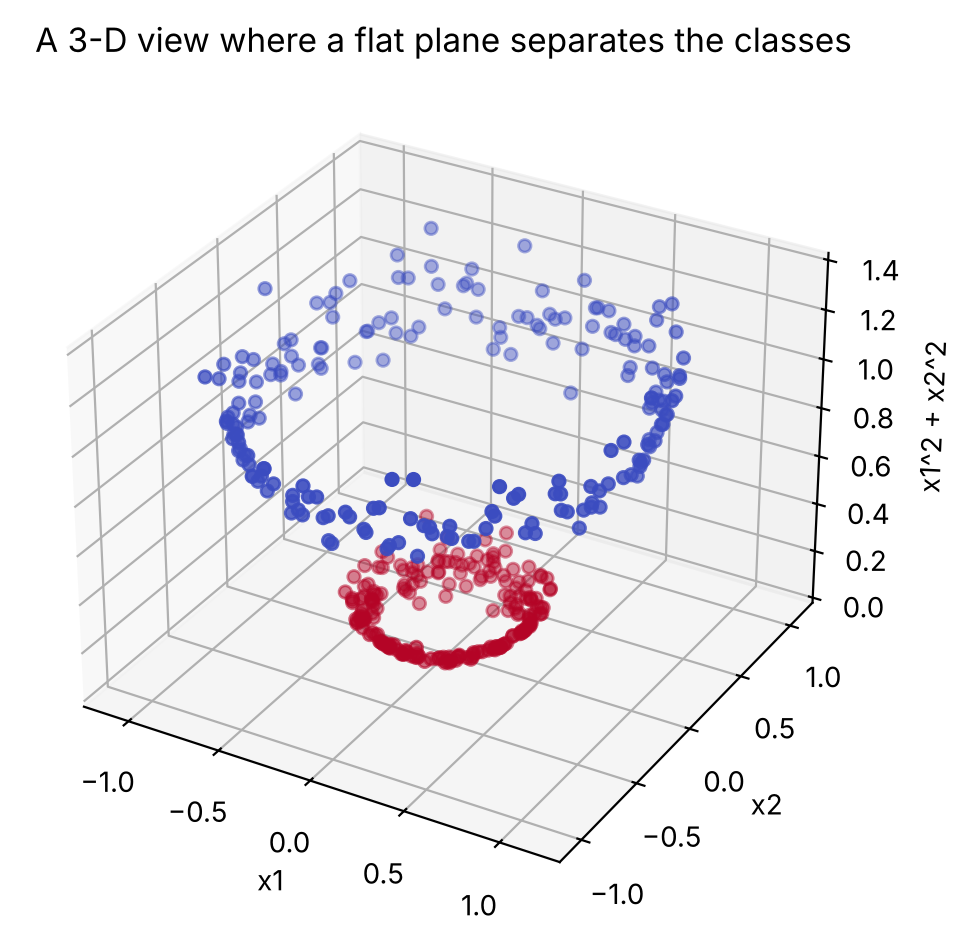

Class 0 r^2 range: 0.77-1.34 | Class 1 r^2 range: 0.07-0.31


In [11]:
for k in range(1, 10):
    Zk = PCA(n_components=k).fit_transform(Xp_s)
    Xtr, Xte, ytr, yte = train_test_split(Zk, yc, test_size=0.3, random_state=42, stratify=yc)
    clf = LogisticRegression(max_iter=5000, C=100).fit(Xtr, ytr)
    print("PCs=%d  cumulative var=%.3f  linear test acc=%.3f" % (k, PCA(n_components=k).fit(Xp_s).explained_variance_ratio_.sum(), clf.score(Xte, yte)))

# The radius feature r^2 = x1^2 + x2^2 is a LINEAR combination of the polynomial terms
r2 = Xc[:,0]**2 + Xc[:,1]**2
fig = plt.figure(figsize=(6.5, 5.5)); ax = fig.add_subplot(projection="3d")
ax.scatter(Xc[:,0], Xc[:,1], r2, c=yc, cmap="coolwarm", s=20)
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_zlabel("x1^2 + x2^2")
ax.set_title("A 3-D view where a flat plane separates the classes"); plt.show()
print("Class 0 r^2 range: %.2f-%.2f | Class 1 r^2 range: %.2f-%.2f" % (r2[yc==0].min(), r2[yc==0].max(), r2[yc==1].min(), r2[yc==1].max()))

---
# Observations & Written Answers

### 2.4 PCA on Iris
PC1 explains **72.96%** and PC2 **22.85%** of the standardized variance; together **95.81%**. **Yes — the first two PCs retain more than 90%** (the remaining two PCs add only 3.67% and 0.52%), so the 4-D data can be shown in 2-D with little loss.

### 3.4 K-Means on blobs (K = 2, 3, 4)
Inertia: K=2 → **2752.93**, K=3 → **283.60**, K=4 → **242.85**.
Inertia never increases as K grows (at K = n it would be 0), so choosing the K with the lowest inertia would always pick the largest K. It measures compactness only and has no penalty for splitting a real cluster in two. The right K is where the curve bends (the elbow: huge drop 2→3, small drop 3→4) and can be confirmed with a metric like the silhouette score, which peaks at **K=3 (0.845)** and falls for K=2 (0.704) and K=4 (0.690).

### Random init vs K-Means++
With `n_init=10` both reach the same inertia (283.60), because the best of 10 restarts hides the difference. With a single initialization over 200 seeds: random init averaged inertia **697.0** (worst 2737.6) and got stuck in a bad local optimum in **34/200 runs**, taking 3.44 iterations on average; K-Means++ reached 283.60 on **all 200** runs in 2.0 iterations. K-Means++ is more stable and faster, though it still does not guarantee the global optimum.

### 4.4 DBSCAN on moons
| eps | clusters | noise |
|---|---|---|
| 0.15 | 16 | 26 |
| 0.30 | 2 | 0 |
| 0.50 | 2 | 0 |

eps=0.15 is too small: neighborhoods are too sparse, so each moon shatters into many small clusters and many points become noise. eps=0.30 recovers the two moons exactly. eps=0.50 still gives two clusters here (the gap between moons is large enough after standardization), but a larger eps would eventually bridge the gap and merge them. K-Means cuts the moons with a straight boundary, because it assumes compact, roughly spherical clusters.

### 4.4 (second) Polynomial features + PCA (3-D)
* Concentric circles are **not linearly separable** in 2-D: a linear classifier scores ~52% (chance).
* Degree-3 polynomial features lift the data into 9-D, where a **linear classifier scores 100%**. The ring radius x1² + x2² is a linear combination of the new features (x1², x2²), so a flat hyperplane separates the classes (class 0 has r² in 0.77–1.34, class 1 in 0.07–0.31).
* **However, the 3-D PCA view is not linearly separable** (~52–56% accuracy). The three leading PCs capture only 65.7% of the variance, and PCA is unsupervised, so it keeps high-variance directions, not the class-separating one. Separability only returns when **5 PCs** are kept (100%).
* Conclusion: the polynomial transformation does make the data linearly separable, but a 3-D PCA projection can hide that. For visualization, a hand-picked 3-D view such as (x1, x2, x1²+x2²) shows the separating plane clearly. Supervised reduction (e.g. LDA) or checking separability in the full transformed space is more reliable than judging from a PCA plot alone.
